# Chapter 09 — 주문 금액의 시간순 회귀 검증

## 1. 예측 문제와 시점 (코드 실행 전 정의)

| 질문 | 정의 |
|---|---|
| 무엇을 예측하는가? | 주문 1건의 `order_total` (원) |
| 예측 단위는? | `order_id`로 구분되는 주문 1건 |
| 언제 예측하는가? | 주문 헤더와 결제 수단이 기록된 직후, 주문 상세의 수량·가격·합계가 분석 시스템에 반영되기 전 |
| 그때 알 수 있다고 가정한 정보는? | 주문 날짜에서 얻은 월·요일, 주문 당시 고객의 나이·성별·도시, 선택된 결제 수단 |

`line_total = quantity × unit_price`, `order_total = order_id별 line_total 합계`로 정답을 만든다. 실제 시스템의 기록 시각이 데이터에 없으므로 위 가용 시점은 **분석 가정**이다. 결제 수단이나 고객 속성이 그때 실제로 제공되지 않는 운영 환경에는 이 평가를 그대로 적용할 수 없다. 주문 상세가 이미 사용 가능하다면 금액은 합산으로 계산해야 하며 이 회귀모델을 쓸 이유가 없다.

입력: 저장소의 `data/raw/{orders,order_items,customers}.csv`. 재현 명령: `python scripts/prepare_ch09_data.py` 다음 `python scripts/run_regression_analysis.py`. Notebook도 같은 함수를 실행한다.

## 2. Target·키·관계 검증

원본의 주문 키, 상세 키, 고객 키 중복과 누락, 상세 없는 주문, 고아 상세, 고객 FK, 수량·가격 결측과 음수, 날짜 파싱을 검사한다. 상세에서 `line_total`을 만든 뒤 주문별 합계로 `order_total`을 만든다. `orders ↔ order_total`은 `one_to_one`, `orders → customers`는 `many_to_one`으로 병합을 강제한다. 하나라도 실패하면 예외를 내고 모델링을 멈춘다.

원본 파일에는 독립적인 `line_total`·`order_total` 정답 열이 없다. 따라서 산식과 집계·병합의 일관성은 확인할 수 있지만, 외부 거래 원장과 금액을 대조한 것은 아니다.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "chapter09":
    root = root.parent
sys.path.insert(0, str(root / "scripts"))
from prepare_ch09_data import prepare
from run_regression_analysis import run, FEATURES, FORBIDDEN

order_data, source_checks = prepare()
print(f"주문 {len(order_data):,}건 / 주문 상세와 고객 관계 검사 {len(source_checks)}개")
display(pd.DataFrame({"check": list(source_checks), "result": ["PASS" if v else "FAIL" for v in source_checks.values()]}))

주문 300건 / 주문 상세와 고객 관계 검사 16개


,check,result
0,orders_pk_unique,PASS
1,items_pk_unique,PASS
2,customers_pk_unique,PASS
3,orders_keys_present,PASS
4,items_keys_present,PASS
5,customers_key_present,PASS
6,all_orders_have_details,PASS
7,items_fk_valid,PASS
8,customers_fk_valid,PASS
9,line_inputs_present,PASS


## 3. Feature Leakage Audit

사용 Feature는 `order_month`, `order_dayofweek`, `age`, `payment_method`, `gender`, `city`로 한정한다. `order_total`은 Target 자체다. `line_total`, `quantity`, `unit_price`, `item_count`, `total_quantity`, `avg_unit_price`는 Target 계산에 쓰이거나 주문 상세를 요약하므로 예측 시점에 금지한다. `order_status`는 사후 상태여서 미래 정보를 담을 수 있다. `order_id`, `customer_id`, `product_id`는 식별자이며 일반화 가능한 사전 정보가 아니고, 특히 `product_id`는 당시 접근할 수 없다고 정의한 상세 정보다. 고객 이름과 가입일도 사용하지 않는다. 모델 입력 열과 금지 열의 교집합을 코드로 확인한다.

In [2]:
overlap = sorted(set(FEATURES) & FORBIDDEN)
print("사용 Feature:", FEATURES)
print("금지 Feature 중복:", overlap)
assert len(overlap) == 0

사용 Feature: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city']
금지 Feature 중복: []


## 4. 시간순 Train / Final Test, Train CV, 모델 선택 고정

마지막 **두 달 전체**를 Final Test로 떼며 같은 날짜의 주문은 경계를 넘지 않게 한다. Train 안에서는 고유 주문 날짜에 `TimeSeriesSplit(n_splits=5)`를 적용한다. 각 fold의 학습 데이터로만 결측값 대치, 숫자 스케일링, 범주형 인코딩을 적합한다. 범주에 처음 보는 값이 나오면 무시한다. 비교 모델은 평균 Baseline, 선형회귀, 랜덤포레스트다. 선택 규칙은 **5개 fold의 MAE 평균 최소, 동률이면 모델명 순**으로 사전에 고정한다. 아래 `run()`은 이 선택을 확정한 다음에야 Final Test 예측을 계산한다.

In [3]:
result = run()
print("Train:", len(result["train"]), "건,", result["train"].order_date.min().date(), "~", result["train"].order_date.max().date())
print("Final Test:", len(result["test"]), "건,", result["test"].order_date.min().date(), "~", result["test"].order_date.max().date())
assert result["train"].order_date.max() < result["test"].order_date.min()
display(result["summary"].round(2))
print("Train CV에서 고정한 Selected Model:", result["selected"])

Train: 267 건, 2025-09-15 ~ 2026-07-31
Final Test: 33 건, 2026-08-02 ~ 2026-09-15


,model,mean,std,min,max
0,Baseline Mean,431169.74,59586.92,361974.00,518881.84
2,Random Forest,453442.18,63786.17,390066.83,559640.47
1,Linear Regression,598646.62,247430.39,389812.15,976307.64


Train CV에서 고정한 Selected Model: Baseline Mean


### Train CV 해석

Baseline 평균 MAE는 약 **431,170원**, Random Forest는 **453,442원**, Linear Regression은 **598,647원**이다. Baseline의 fold MAE 범위는 **361,974~518,882원**으로 변동이 있다. 선형회귀는 첫 fold에서 약 **976,308원**까지 악화되어 안정성이 낮다. Random Forest도 모든 fold에서 Baseline을 꾸준히 이기지 못했다. 따라서 Final Test를 보기 전에 **Baseline Mean**을 선택 모델로 고정한다. 복잡한 모델의 추가 가치는 이 CV에서 확인되지 않았다.

## 5. Final Test: Baseline Mean vs Frozen Selected Model

선택된 모델이 Baseline 자체이므로 두 행의 예측과 지표가 일치하는 것이 정상이다. Final Test에서 다른 후보를 다시 비교하거나 모델을 교체하지 않는다.

In [4]:
display(result["final"].round(3))
print("Baseline 대비 선택 모델 MAE 개선율: {:.2f}%".format(result["final"].iloc[1].baseline_mae_improvement_pct))

,model,selected_model,test_rows,MAE,RMSE,R2,baseline_mae_improvement_pct
0,Baseline Mean,Baseline Mean,33,397504.937,468456.287,-0.03,0.0
1,Frozen Selected Model,Baseline Mean,33,397504.937,468456.287,-0.03,0.0


Baseline 대비 선택 모델 MAE 개선율: 0.00%


### 지표 해석

Final Test의 MAE는 약 **397,505원**으로, 주문 한 건당 평균 절대 오차가 그 정도라는 뜻이다. RMSE는 약 **468,456원**으로 MAE보다 커서 일부 큰 오차의 영향이 있다. R²는 **−0.030**으로, 이 기간의 정답 평균을 사후에 사용한 단순 기준보다 설명력이 낮다. 음수 R² 자체가 코드 오류를 뜻하지 않는다. Baseline 대비 MAE 개선율은 **0%**다. 선택 모델이 Baseline이므로 복잡한 모델을 운영할 근거는 없다.

## 6. 큰 오차 사례

`residual = actual − predicted`로 정의한다. 아래는 Final Test에서 절대 오차 상위 3건이다.

In [5]:
display(result["errors"][["order_id", "order_date", "actual_order_total", "predicted_order_total", "residual", "abs_error"]].head(3).round(2))

/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/ipykernel_69401/2926767580.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(result["errors"][["order_id", "order_date", "actual_order_total", "predicted_order_total", "residual", "abs_error"]].head(3).round(2))


,order_id,order_date,actual_order_total,predicted_order_total,residual,abs_error
298,204,2026-09-15,1800000,860887.64,939112.36,939112.36
294,73,2026-09-12,72000,860887.64,-788887.64,788887.64
269,264,2026-08-11,102000,860887.64,-758887.64,758887.64


| 주문 | 관찰된 결과 | 가능한 이유 (가설) | 추가 확인 데이터 | 현재 모델의 한계 |
|---|---|---|---|---|
| 204 | 실제 1,800,000원, 예측 약 860,888원; 약 939,112원 과소예측 | 주문 상세의 품목·수량·단가 때문에 큰 금액일 수 있음 | 해당 주문의 상세 품목, 수량, 단가 | 평균 예측은 주문별 큰 장바구니를 구분하지 못함 |
| 73 | 실제 72,000원, 예측 약 860,888원; 약 788,888원 과대예측 | 소액 품목 또는 적은 수량일 수 있음 | 해당 주문의 상세 품목, 수량, 단가 | 평균 예측은 소액 주문을 구분하지 못함 |
| 264 | 실제 102,000원, 예측 약 860,888원; 약 758,888원 과대예측 | 소액 장바구니일 수 있음 | 해당 주문의 상세 품목, 수량, 단가 | 같은 평균값을 내므로 주문 간 규모 차이를 반영하지 못함 |

가능한 이유는 데이터 확인 전의 가설이다. 상세 정보는 사후 오차 분석에는 사용할 수 있지만 이번 예측 시점의 모델 Feature로 넣을 수 없다.

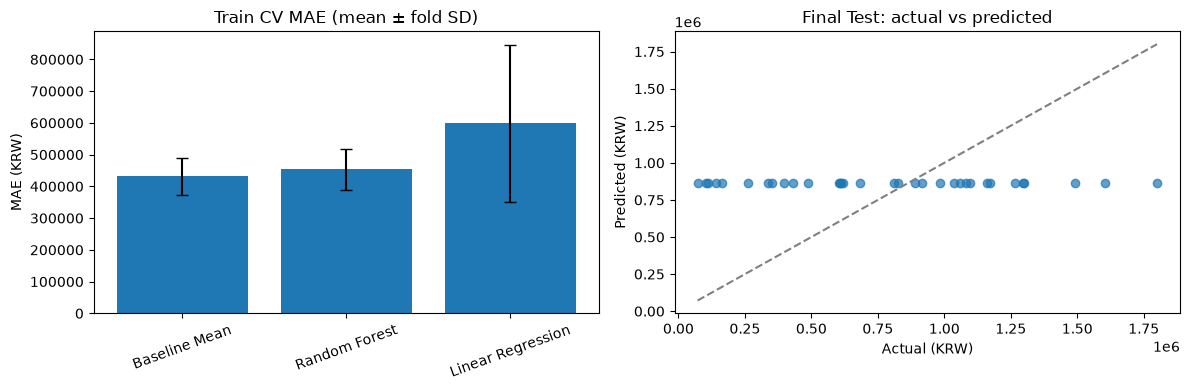

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary = result["summary"].sort_values("mean")
axes[0].bar(summary.model, summary["mean"], yerr=summary["std"], capsize=4)
axes[0].set_title("Train CV MAE (mean ± fold SD)")
axes[0].set_ylabel("MAE (KRW)")
axes[0].tick_params(axis="x", rotation=20)
e = result["errors"]
axes[1].scatter(e.actual_order_total, e.predicted_order_total, alpha=.7)
lo, hi = min(e.actual_order_total.min(), e.predicted_order_total.min()), max(e.actual_order_total.max(), e.predicted_order_total.max())
axes[1].plot([lo, hi], [lo, hi], "--", color="gray")
axes[1].set_title("Final Test: actual vs predicted")
axes[1].set_xlabel("Actual (KRW)")
axes[1].set_ylabel("Predicted (KRW)")
plt.tight_layout()
plt.show()

## 7. LLM 활용 및 검증

LLM은 누수 가능 열 검토, Python 파이프라인과 지표 설명 초안에 사용했다. 제안은 실제 데이터와 Train CV 결과로 검증했다.

| LLM 보조 제안·검토 항목 | 실제 확인 | 결정 |
|---|---|---|
| 주문 상세의 `item_count`·`avg_unit_price`처럼 금액을 잘 설명할 수 있는 열 | 두 열은 상세 수량·가격으로 계산되며 정의한 예측 시점에는 사용 불가 | 누수 위험으로 제외 |
| 날짜·고객 속성·결제 수단을 후보 Feature로 사용 | 원본 열과 결측 여부를 확인하고 금지 열과의 교집합 0을 코드로 검증 | 시점 가정을 명시하고 사용 |
| Linear Regression, Random Forest를 Baseline과 비교 | 5개 Train CV 평균 MAE가 모두 Baseline보다 높음 | 두 후보 보류, Baseline 선택 |
| R²가 음수이면 코드 오류일 가능성 | Target·병합·시간순 분할을 검증했고 Final Test의 R²는 −0.030 | 낮은 설명력으로 해석 |

성능을 높이기 위해 금지 Feature를 추가하거나 Final Test를 보고 선택 모델을 바꾸지 않았다.

## 8. 자동 Validation과 최종 판단

`reports/ch09_regression_validation.csv`의 핵심 조건을 확인한다. 모든 조건이 PASS여야 완료로 본다.

In [7]:
validation = pd.read_csv(root / "reports" / "ch09_regression_validation.csv")
display(validation.T.rename(columns={0: "result"}))
assert validation.loc[0, "forbidden_feature_overlap"] == 0
assert validation.drop(columns="forbidden_feature_overlap").eq("PASS").all().all()

,result
forbidden_feature_overlap,0
strict_train_before_test,PASS
selected_model_exists_in_train_cv,PASS
final_test_contains_baseline,PASS
final_test_contains_frozen_selected_model,PASS
test_rows_for_r2,PASS
source_checks,PASS


### 최종 판단: 현재 데이터로는 사용 보류

누수 검사는 통과했고, Train의 모든 CV fold 및 Train–Final Test 경계는 시간순이다. 전처리도 학습 fold 안에서 적합했다. 그러나 Train CV에서 복잡한 두 모델이 Baseline 평균 MAE를 이기지 못했고, 선택된 Baseline의 fold 오차도 변동이 있다. Final Test에서는 MAE 약 397,505원, RMSE 약 468,456원, R² −0.030, Baseline 대비 개선율 0%다. 큰 주문 1건과 소액 주문 2건에서 약 76만~94만원의 오차가 관찰됐다. 데이터는 300건뿐이고 주문 상세 가용 시각과 고객 속성의 당시 값이 확인되지 않아 실제 운영 시점의 정보 가용성도 추가 검증해야 한다. 따라서 주문별 금액 예측 용도로는 현재 데이터로 사용을 보류한다.

재현 결과 파일: `chapter09/data/ch09_order_level.csv`, `chapter09/data/ch09_source_checks.csv`, `reports/ch09_train_cv_folds.csv`, `reports/ch09_train_cv_summary.csv`, `reports/ch09_final_test_metrics.csv`, `reports/ch09_final_test_predictions.csv`, `reports/ch09_regression_validation.csv`.

이 데이터는 `scripts/generate_sample_data.py`로 만든 **가상 쇼핑몰 표본**이다. 주문 상태에 취소·환불도 포함되지만 이번 Target은 상태를 반영한 순매출이 아닌 **주문 상세의 명목 합계**다. 고객 나이는 주문 시점 이력으로 보존된 값이 아니므로 실제 서비스에서는 주문 당시 값과 기록 시각을 확인해야 한다. 생성 스크립트는 실행 날짜를 기준으로 날짜를 새로 뽑으므로, 현재 결과를 재현할 때는 저장소의 원본 CSV를 그대로 사용한다.